In [5]:
!pip install scikit-learn 

In [6]:
!pip install tensorflow

# Recursive Least Squares (RLS) Method for Univariate method.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import pearsonr  # For Pearson correlation

# Load and preprocess data
df = pd.read_csv("Bandwidth_synthetic_data_1.csv").dropna()
feature = 'RSSI'  # it would be another features
target = 'Bandwidth'

X = df[[feature]].values
y = df[target].values.reshape(-1, 1)

# Normalize feature and target
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Initialize RLS parameters
n = X_scaled.shape[0]
theta = np.zeros((1, 1))                # Initial weights
P = np.eye(1) * 1000                    # High initial covariance
lambda_factor = 0.99                    # Forgetting factor

# Store predictions
y_preds = []

# Recursive Least Squares Loop
for t in range(n):
    x_t = X_scaled[t].reshape(-1, 1)    # Current input
    y_t = y_scaled[t]                   # Actual output

    # Gain vector
    numerator = P @ x_t
    denominator = lambda_factor + x_t.T @ P @ x_t
    K_t = numerator / denominator

    # Prediction
    y_hat = x_t.T @ theta
    y_preds.append(y_hat[0][0])

    # Update weights
    error = y_t - y_hat
    theta = theta + K_t * error

    # Update covariance
    P = (P - K_t @ x_t.T @ P) / lambda_factor

# Convert predictions back to original scale
y_preds = np.array(y_preds).reshape(-1, 1)
y_preds_actual = scaler_y.inverse_transform(y_preds)
y_actual = scaler_y.inverse_transform(y_scaled)

# Evaluation
mse = mean_squared_error(y_actual, y_preds_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_preds_actual)
pearson_corr, _ = pearsonr(y_actual.flatten(), y_preds_actual.flatten())  # Pearson correlation

# Print metrics
print(f"RLS Results:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Pearson Correlation Coefficient: {pearson_corr:.4f}")




RLS Results:
MSE: 12.9754
RMSE: 3.6021
R² Score: -0.1010
Pearson Correlation Coefficient: 0.5017


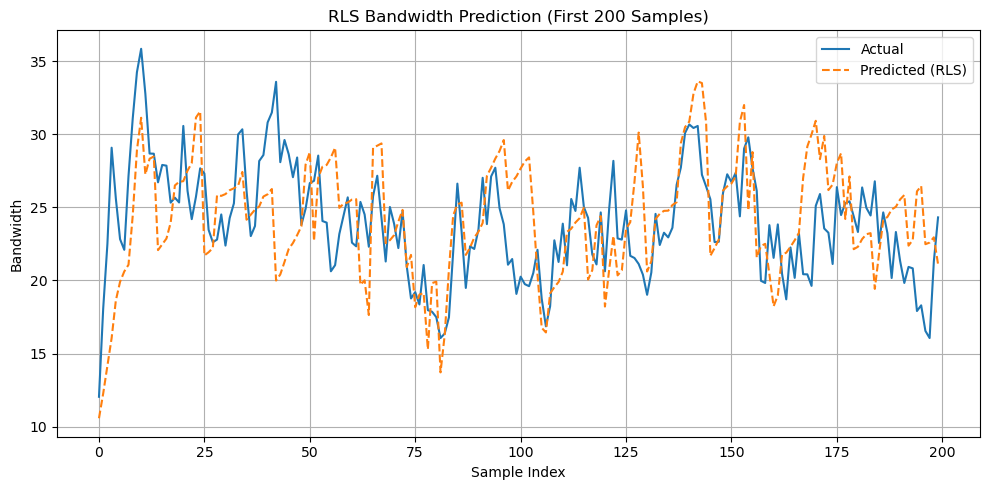

In [8]:
# Plot predictions vs actual
plt.figure(figsize=(10, 5))
plt.plot(y_actual[:200], label='Actual')
plt.plot(y_preds_actual[:200], label='Predicted (RLS)', linestyle='--')
plt.title("RLS Bandwidth Prediction (First 200 Samples)")
plt.xlabel("Sample Index")
plt.ylabel("Bandwidth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Recursive Least Squares (RLS) Method for Multivariate method.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import pearsonr

# Load and preprocess data
df = pd.read_csv("Bandwidth_synthetic_data_1.csv").dropna()
features = ['RSSI', 'RSRQ', 'Speed', 'TA', 'LTE_Neighbour', 'Band', 'Echng']
target = 'Bandwidth'

X = df[features].values
y = df[target].values.reshape(-1, 1)

# Normalize features and target
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Initialize RLS parameters
n_samples, n_features = X_scaled.shape
theta = np.zeros((n_features, 1))       # Initial weight vector
P = np.eye(n_features) * 1000           # Large initial covariance matrix
lambda_factor = 0.99                    # Forgetting factor

# Store predictions
y_preds = []

# Recursive Least Squares Loop
for t in range(n_samples):
    x_t = X_scaled[t].reshape(-1, 1)    # Shape (n_features, 1)
    y_t = y_scaled[t]                   # Shape (1,)

    # Compute gain vector
    numerator = P @ x_t
    denominator = lambda_factor + x_t.T @ P @ x_t
    K_t = numerator / denominator

    # Make prediction
    y_hat = x_t.T @ theta
    y_preds.append(y_hat[0][0])

    # Update weights
    error = y_t - y_hat
    theta = theta + K_t * error

    # Update covariance matrix
    P = (P - K_t @ x_t.T @ P) / lambda_factor

# Convert predictions back to original scale
y_preds = np.array(y_preds).reshape(-1, 1)
y_preds_actual = scaler_y.inverse_transform(y_preds)
y_actual = scaler_y.inverse_transform(y_scaled)

# Evaluation metrics
mse = mean_squared_error(y_actual, y_preds_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_preds_actual)
pearson_corr, _ = pearsonr(y_actual.flatten(), y_preds_actual.flatten())

# Print results
print("Multivariate RLS Results:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Pearson Correlation Coefficient: {pearson_corr:.4f}")




Multivariate RLS Results:
MSE: 3.9930
RMSE: 1.9983
R² Score: 0.6612
Pearson Correlation Coefficient: 0.8131


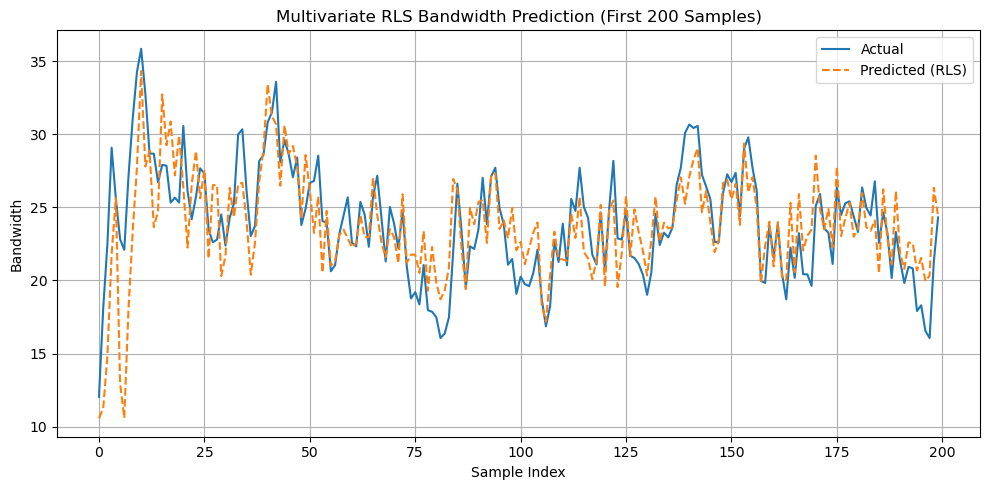

In [10]:
# Plot actual vs predicted
plt.figure(figsize=(10, 5))
plt.plot(y_actual[:200], label='Actual')
plt.plot(y_preds_actual[:200], label='Predicted (RLS)', linestyle='--')
plt.title("Multivariate RLS Bandwidth Prediction (First 200 Samples)")
plt.xlabel("Sample Index")
plt.ylabel("Bandwidth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()